# Notebook 01: Data and the Exact Model

**Delivery Optimization (Capacitated Vehicle Routing Problem)**
IT50802 Optimization Methods, MSc in AI, SLIIT

Owner: **M.Z.M. Ruzbihan (MS26911458)** · Group member: Luminda De Silva (MS26903224)

This notebook covers:

1. what the real dataset contains and how we clean it,
2. the assumptions we add, and why,
3. the distance matrix,
4. the mathematical formulation (Integer Linear Program),
5. a live run of the exact method, and evidence that it is correct and that it does not scale.

All logic lives in `src/`. This notebook only calls those functions and shows the results.

In [1]:
import sys
from pathlib import Path

# Make the repository root importable when the notebook runs from notebooks/
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data_prep import (VEHICLE_CAPACITY_KG, VAN_VOLUME_DM3, load_raw, clean_customers,
                           depot_location, haversine_km, make_instance, sample_instance)
from src.exact_ilp import build_model, solve_cvrp_ilp

FIGURES = REPO_ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 120)

## 1. The raw dataset

Source: Kaggle, *Customer Information* by batoulmahvash (`Customer Data.xlsx`, sheet `Customer Data`).
See `data/README.md` for the download command. The file is not stored in the repository because its licence is listed as "Unknown".

In [2]:
raw = load_raw()
print(f"Raw sheet: {raw.shape[0]} rows x {raw.shape[1]} columns")
print("Columns:", list(raw.columns))
print(f"Rows with a CUSTOMER ID: {raw['CUSTOMER ID'].notna().sum()}")
print(f"Rows WITHOUT a CUSTOMER ID: {raw['CUSTOMER ID'].isna().sum()}")
raw.head()

Raw sheet: 25734 rows x 7 columns
Columns: ['CUSTOMER ID', 'LATITUDE', 'LONGITUDE', 'PRIORITY', 'OPERATING SLOTS', 'Order size (weight in kg)', 'Order size (volume in dm^3)']
Rows with a CUSTOMER ID: 87
Rows WITHOUT a CUSTOMER ID: 25647


,CUSTOMER ID,LATITUDE,LONGITUDE,PRIORITY,OPERATING SLOTS,Order size (weight in kg),Order size (volume in dm^3)
0,1.0,24.135818,55.874584,3.0,NaN,141.0,82.4
1,2.0,24.471692,54.408903,2.0,10:00 AM - 07:00 PM,94.0,43.1
2,3.0,24.424576,54.643758,3.0,NaN,31.4,20.1
3,4.0,24.349938,54.559103,1.0,08:00 AM - 11:00 AM,181.8,99.3
4,5.0,24.548879,54.723856,2.0,08:00 AM - 09:00 AM,129.0,56.8


**Data quality issue.** Only 87 rows are real customers. The thousands of rows below them hold only an
`OPERATING SLOTS` value (or nothing). They look like spreadsheet fill-down leftovers. The tail of the sheet shows this:

In [3]:
raw.iloc[85:92]

,CUSTOMER ID,LATITUDE,LONGITUDE,PRIORITY,OPERATING SLOTS,Order size (weight in kg),Order size (volume in dm^3)
85,86.0,25.407778,55.544783,2.0,08:00 AM - 01:00 PM,38.6,20.1
86,87.0,24.364441,54.571244,1.0,08:00 AM - 08:00 PM,87.2,44.8
87,NaN,NaN,NaN,NaN,NaN,NaN,NaN
88,NaN,NaN,NaN,NaN,NaN,NaN,NaN
89,NaN,NaN,NaN,NaN,NaN,NaN,NaN
90,NaN,NaN,NaN,NaN,NaN,NaN,NaN
91,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Cleaning

`clean_customers()` keeps rows that have a `CUSTOMER ID`, converts types, rounds weight and volume to 1 decimal
(the file contains values like `43.10000000000001`), and checks that exactly 87 unique customers remain.

In [4]:
customers = clean_customers(raw)
print(f"Clean customers: {len(customers)}")
customers.head(10)

Clean customers: 87


,customer_id,lat,lon,priority,time_slot,weight_kg,volume_dm3
0,1,24.135818,55.874584,3,NaN,141.0,82.4
1,2,24.471692,54.408903,2,10:00 AM - 07:00 PM,94.0,43.1
2,3,24.424576,54.643758,3,NaN,31.4,20.1
3,4,24.349938,54.559103,1,08:00 AM - 11:00 AM,181.8,99.3
4,5,24.548879,54.723856,2,08:00 AM - 09:00 AM,129.0,56.8
5,6,24.442075,54.404505,3,10:00 AM - 06:00 PM,24.2,28.8
6,7,24.301933,54.712182,2,09:00 AM - 10:00 AM,111.4,40.8
7,8,24.498228,54.481054,2,10:00 AM - 06:00 PM,28.2,20.1
8,9,24.501733,54.676199,2,08:00 AM - 02:00 PM,56.0,20.1
9,10,24.334936,54.612764,2,10:00 AM - 03:00 PM,136.4,49.1


In [5]:
summary = customers[["lat", "lon", "weight_kg", "volume_dm3"]].describe().round(3)
summary

,lat,lon,weight_kg,volume_dm3
count,87.000,87.000,87.000,87.000
mean,24.967,55.154,115.315,58.478
std,0.455,0.495,49.624,25.650
min,24.136,54.337,20.800,20.100
25%,24.472,54.647,79.100,39.050
50%,25.125,55.308,115.000,55.300
75%,25.309,55.472,158.400,80.550
max,25.805,56.322,198.400,110.000


In [6]:
total_weight = customers["weight_kg"].sum()
print("Priority counts:", customers["priority"].value_counts().sort_index().to_dict())
print("Customers without a time slot:", customers["time_slot"].isna().sum(), "of", len(customers))
print(f"Total weight: {total_weight:.1f} kg | total volume: {customers['volume_dm3'].sum():.1f} dm3")
print(f"Largest single order: {customers['weight_kg'].max():.1f} kg, {customers['volume_dm3'].max():.1f} dm3")
print(f"Lower bound on vans at Q = {VEHICLE_CAPACITY_KG:.0f} kg: ceil({total_weight:.1f} / {VEHICLE_CAPACITY_KG:.0f}) = "
      f"{math.ceil(total_weight / VEHICLE_CAPACITY_KG)}")

Priority counts: {1: 21, 2: 37, 3: 29}
Customers without a time slot: 24 of 87
Total weight: 10032.4 kg | total volume: 5087.6 dm3
Largest single order: 198.4 kg, 110.0 dm3
Lower bound on vans at Q = 1000 kg: ceil(10032.4 / 1000) = 11


### What we use, and what is missing

| Column | Used? | Role in the model |
|---|---|---|
| `LATITUDE`, `LONGITUDE` | Yes | Distances $d_{ij}$ |
| `Order size (weight in kg)` | Yes | Demand $q_i$ (capacity constraint) |
| `Order size (volume in dm^3)` | Checked after solving | Assumption A6 |
| `PRIORITY` | No | Meaning of 1/2/3 is not documented |
| `OPERATING SLOTS` | No | 24 of 87 are blank; no speeds or service times exist (future work: VRPTW) |

The dataset has **no depot, no vehicle data and no road distances**. The brief allows synthetic or assumed data
when it is explained and justified, so we add these assumptions:

| ID | Assumption | Justification |
|---|---|---|
| A1 | One depot at the centroid of all 87 customers | Neutral and reproducible; the data gives no depot |
| A2 | Great-circle (haversine) distance in km | Only coordinates are available; underestimates road distance |
| A3 | Van capacity $Q$ = 1,000 kg | Typical light commercial van payload; 600 and 1,500 kg tested later |
| A4 | Unlimited identical vans | Standard CVRP; the number of vans is an output |
| A5 | Time windows and priority not modelled | Missing values and undocumented meaning |
| A6 | Volume checked after solving (van volume 3,000 dm³) | Largest order is 110 dm³, so weight is the binding resource |
| A7 | Exact-method instances are random subsets with fixed seeds | The ILP cannot solve all 87; seeds make subsets reproducible |

## 3. Customer map

Real coordinates (they appear to lie in the UAE). Dot size shows order weight and colour shows priority.
The black square is the **assumed** depot (A1). It is not part of the data.

Depot (centroid): lat 24.9670, lon 55.1540


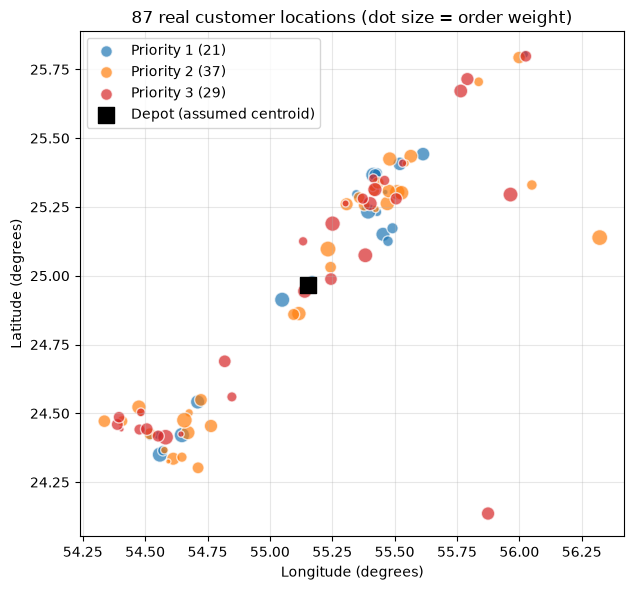

In [7]:
depot = depot_location(customers)
print(f"Depot (centroid): lat {depot[0]:.4f}, lon {depot[1]:.4f}")

fig, ax = plt.subplots(figsize=(9, 6))
colours = {1: "tab:blue", 2: "tab:orange", 3: "tab:red"}
for priority, group in customers.groupby("priority"):
    ax.scatter(group["lon"], group["lat"], s=group["weight_kg"] / 1.5, alpha=0.7,
               color=colours[priority], edgecolor="white", label=f"Priority {priority} ({len(group)})")
ax.scatter(depot[1], depot[0], marker="s", s=120, color="black", label="Depot (assumed centroid)")
ax.set_xlabel("Longitude (degrees)")
ax.set_ylabel("Latitude (degrees)")
ax.set_title("87 real customer locations (dot size = order weight)")
ax.set_aspect(1 / math.cos(math.radians(depot[0])))   # so 1 km looks the same in both directions
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES / "f1_customer_map.png", dpi=200)
plt.show()

## 4. Distance matrix

For two points with latitudes $\varphi_1, \varphi_2$ and longitudes $\lambda_1, \lambda_2$ (in radians), the haversine distance is

$$
d = 2R \arcsin\left(\sqrt{\sin^2\!\left(\tfrac{\varphi_2-\varphi_1}{2}\right) + \cos\varphi_1 \cos\varphi_2 \sin^2\!\left(\tfrac{\lambda_2-\lambda_1}{2}\right)}\right), \qquad R = 6371 \text{ km}
$$

Node 0 is the depot and nodes $1..n$ are customers, so the full matrix is $88 \times 88$.

In [8]:
full = make_instance(customers, depot, name="all_87")
dist = full["dist"]
off_diagonal = dist[~np.eye(len(dist), dtype=bool)]
print(f"Matrix size: {dist.shape}")
print(f"Symmetric: {np.allclose(dist, dist.T)} | zero diagonal: {np.all(np.diag(dist) == 0)}")
print(f"Shortest distance: {off_diagonal.min():.2f} km | longest: {off_diagonal.max():.2f} km")
print(f"Sanity check, 1 degree of latitude: {haversine_km(0, 0, 1, 0):.2f} km (expected 111.19)")
pd.DataFrame(dist[:6, :6], index=[f"node {i}" for i in range(6)],
             columns=[f"node {j}" for j in range(6)]).round(2)

Matrix size: (88, 88)
Symmetric: True | zero diagonal: True
Shortest distance: 0.34 km | longest: 225.27 km
Sanity check, 1 degree of latitude: 111.19 km (expected 111.19)


,node 0,node 1,node 2,node 3,node 4,node 5
node 0,0.00,117.71,93.26,79.34,91.23,63.63
node 1,117.71,0.00,153.16,128.82,135.48,125.30
node 2,93.26,153.16,0.00,24.34,20.36,33.00
node 3,79.34,128.82,24.34,0.00,11.93,16.02
node 4,91.23,135.48,20.36,11.93,0.00,27.70
node 5,63.63,125.30,33.00,16.02,27.70,0.00


## 5. Mathematical formulation (CVRP as an Integer Linear Program)

**In words:** vans leave the depot, visit customers and return. Every customer is visited exactly once,
no van carries more than $Q$ kg, and we minimise the total distance driven.

**Sets and parameters**

- $V = \{0, 1, \dots, n\}$: all nodes (0 = depot); $C = \{1, \dots, n\}$: customers
- $d_{ij}$: distance from $i$ to $j$ (km) → `instance["dist"]`
- $q_i$: order weight of customer $i$ (kg) → `instance["demand"]`
- $Q$: van capacity (kg) → `instance["capacity"]`

**Decision variables**

- $x_{ij} \in \{0,1\}$: 1 if a van drives directly from $i$ to $j$ → `x[(i, j)]`
- $u_i$: load delivered so far on the route when the van leaves customer $i$ → `u[i]`

**Model**

$$
\min \; Z = \sum_{i \in V} \sum_{j \in V, j \neq i} d_{ij} \, x_{ij} \tag{1}
$$

$$
\sum_{j \in V, j \neq i} x_{ij} = 1 \quad \forall i \in C \tag{2}
$$

$$
\sum_{i \in V, i \neq j} x_{ij} = 1 \quad \forall j \in C \tag{3}
$$

$$
\sum_{j \in C} x_{0j} = \sum_{i \in C} x_{i0} \tag{4}
$$

$$
u_j \ge u_i + q_j - Q(1 - x_{ij}) \quad \forall i, j \in C,\; i \neq j \tag{5}
$$

$$
q_i \le u_i \le Q \quad \forall i \in C, \qquad x_{ij} \in \{0, 1\} \tag{6}
$$

**What each constraint means**

- **(1)** the objective: total kilometres driven.
- **(2), (3)** every customer has exactly one arc out and one arc in, so it is served exactly once.
- **(4)** every van that leaves the depot comes back.
- **(5)** Miller–Tucker–Zemlin (MTZ) load constraint. If $x_{ij}=1$, the load after $j$ is at least the load after $i$ plus $q_j$.
  The load cannot keep growing around a closed loop, so loops that skip the depot (subtours) are impossible.
  If $x_{ij}=0$, the $-Q$ term makes the constraint always true, so it switches off.
- **(6)** together with (5), no route can carry more than $Q$.

**Why it is hard:** CVRP contains the Travelling Salesman Problem as a special case, so it is **NP-hard**.
For one van alone there are $n!$ visiting orders (10! = 3,628,800; 20! ≈ 2.4 × 10¹⁸).

In [9]:
for n in (5, 10, 20, 87):
    variables = n * (n + 1) + n          # x_ij for i != j over n+1 nodes, plus u_i
    mtz = n * (n - 1)                    # constraint (5)
    print(f"n = {n:2d}: about {variables:5d} variables and {2 * n + 1 + mtz:5d} constraints")

n =  5: about    35 variables and    31 constraints
n = 10: about   120 variables and   111 constraints
n = 20: about   440 variables and   421 constraints
n = 87: about  7743 variables and  7657 constraints


## 6. The exact method: branch and bound with CBC

PuLP passes the model to the free **CBC** solver:

1. Solve the **LP relaxation**, where $x_{ij}$ may be anything between 0 and 1. Its value is a **lower bound**:
   no real plan can be shorter.
2. If some $x_{ij}$ is fractional, **branch**: one sub-problem with $x_{ij}=0$ and one with $x_{ij}=1$.
3. Every integer solution found is an **upper bound** (a real plan).
4. **Prune** any sub-problem whose lower bound is already worse than the best plan found. CBC also adds cutting planes.
5. When lower bound = upper bound, the plan is **proven optimal**.

### Live demo: 10 random customers, Q = 600 kg

We use a smaller capacity here so the demo needs more than one van.

In [10]:
instance = sample_instance(customers, n=10, seed=3, capacity=600)
model, _, _ = build_model(instance)
print(f"Instance {instance['name']}: Kaggle customers {instance['customer_ids']}")
print(f"Total demand {sum(instance['demand']):.1f} kg, Q = {instance['capacity']:.0f} kg "
      f"-> at least {math.ceil(sum(instance['demand']) / instance['capacity'])} vans")
print(f"Model: {len(model.variables())} variables, {len(model.constraints)} constraints")

result = solve_cvrp_ilp(instance)
print(f"\nStatus: {result['status']} | total distance: {result['distance_km']:.2f} km | "
      f"runtime: {result['runtime_s']:.2f} s | gap: {result['gap_pct']:.2f} %")
for k, route in enumerate(result["routes"], start=1):
    load = sum(instance["demand"][node] for node in route)
    km = sum(instance["dist"][a][b] for a, b in zip(route, route[1:]))
    kaggle_ids = [instance["customer_ids"][node - 1] for node in route[1:-1]]
    print(f"  Van {k}: Kaggle customers {kaggle_ids} | load {load:.1f} kg | {km:.2f} km")

Instance n10_seed3: Kaggle customers [4, 7, 9, 15, 20, 50, 64, 67, 74, 82]
Total demand 1276.8 kg, Q = 600 kg -> at least 3 vans
Model: 120 variables, 111 constraints



Status: optimal | total distance: 557.91 km | runtime: 5.56 s | gap: 0.00 %
  Van 1: Kaggle customers [9, 4, 7, 82] | load 490.6 kg | 194.81 km
  Van 2: Kaggle customers [15, 74, 50, 67] | load 529.4 kg | 253.54 km
  Van 3: Kaggle customers [64, 20] | load 256.8 kg | 109.56 km


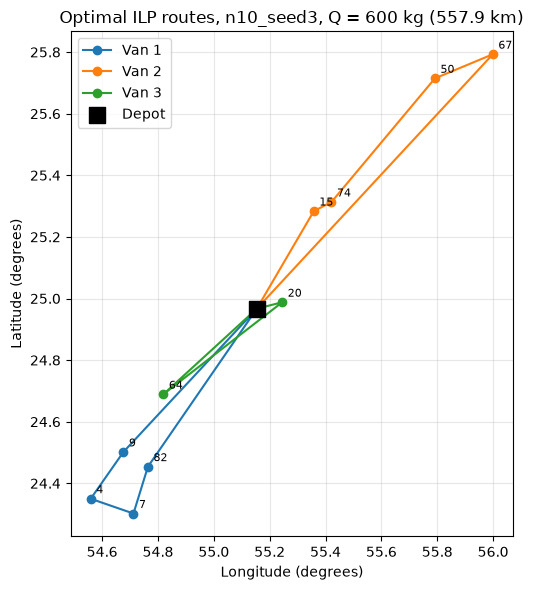

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
lats, lons = instance["lats"], instance["lons"]
for k, route in enumerate(result["routes"], start=1):
    ax.plot([lons[node] for node in route], [lats[node] for node in route], "-o", label=f"Van {k}")
ax.scatter(lons[0], lats[0], marker="s", s=120, color="black", zorder=5, label="Depot")
for node in range(1, len(lats)):
    ax.annotate(str(instance["customer_ids"][node - 1]), (lons[node], lats[node]),
                textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.set_xlabel("Longitude (degrees)")
ax.set_ylabel("Latitude (degrees)")
ax.set_title(f"Optimal ILP routes, {instance['name']}, Q = 600 kg ({result['distance_km']:.1f} km)")
ax.set_aspect(1 / math.cos(math.radians(lats[0])))
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES / "f2a_ilp_routes_n10.png", dpi=200)
plt.show()

## 7. Is the ILP correct? Independent check

`src/verify_exact.py` finds the true optimum by exhaustive dynamic programming (Held–Karp tours plus the best split into vans),
without any solver, and compares it with the ILP. If the formulation were wrong, the numbers would differ.
Run `python -m src.verify_exact` to create the table below.

In [12]:
verification_path = REPO_ROOT / "results" / "tables" / "ilp_verification.csv"
if verification_path.exists():
    display(pd.read_csv(verification_path))
else:
    print("Run `python -m src.verify_exact` first.")

,instance,n_customers,capacity_kg,ilp_status,ilp_distance_km,exhaustive_distance_km,ilp_routes,ilp_runtime_s,match
0,n8_seed1,8,1000,optimal,334.5717,334.5717,1,0.30,True
1,n8_seed2,8,1000,optimal,300.6856,300.6856,2,0.51,True
2,n10_seed1,10,1000,optimal,405.7391,405.7391,2,2.25,True
3,n10_seed2,10,1000,optimal,307.3016,307.3016,2,1.53,True
4,n10_seed3,10,600,optimal,557.9089,557.9089,3,6.27,True
5,n12_seed2,12,1000,optimal,317.6864,317.6864,2,13.04,True


## 8. Why we also need a heuristic

A single larger instance with a 20-second time limit shows what happens as $n$ grows. CBC returns a feasible plan,
but it cannot close the gap between that plan and its lower bound. The full scalability experiment (E2) is in `src/run_comparison.py`.

In [13]:
bigger = sample_instance(customers, n=20, seed=1)
limited = solve_cvrp_ilp(bigger, time_limit=20)
print(f"{bigger['name']}: status {limited['status']} after {limited['runtime_s']:.1f} s")
print(f"Best plan found: {limited['distance_km']:.2f} km | lower bound: {limited['best_bound']:.2f} km | "
      f"gap: {limited['gap_pct']:.1f} %")

n20_seed1: status feasible after 19.8 s
Best plan found: 552.30 km | lower bound: 226.57 km | gap: 59.0 %


## Summary

- The dataset gives 87 real customers with coordinates and order weights. We removed the filler rows and added clearly labelled assumptions A1–A7.
- The CVRP is written as an ILP with MTZ constraints and solved exactly by CBC branch and bound.
- On small instances the ILP finds the proven optimum, and an independent exhaustive search confirms it.
- At 20 customers the solver can no longer prove optimality within the time limit, which reflects NP-hardness.
  This is why the project also uses a heuristic (greedy + simulated annealing, notebook 02).